<a href="https://colab.research.google.com/github/Nicolas-Bernal/Simulacion-Estadistica/blob/main/MARKOV%20CHAIN%20MONTE%20CARLO/Metropolis%20Hasting/METROPOLIS%E2%80%93HASTINGS_ALGORITHM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

7.1, 7.2,7.6, 7.7

# Algunas Simulaciones Metropolis Hasting usando el kernel de R

---




## 7.1.

### *El objetivo de este problema es investigar el papel de la distribución propuesta en un algoritmo de Metropolis–Hastings diseñado para simular a partir de la distribución a posteriori de un parámetro $\delta$. En la parte (a), se le pide que simule datos de una distribución con $\delta$ conocido. Para las partes (b)–(d), asuma que $\delta$ es desconocido con una distribución a priori $\text{Unif}(0,1)$ para $\delta$. Para las partes (b)–(d), proporcione un gráfico adecuado y una tabla que resuma la salida del algoritmo. Para facilitar las comparaciones, utilice el mismo número de iteraciones, semilla aleatoria, valores iniciales y periodo de calentamiento (burn-in) para todas las implementaciones del algoritmo*





* *a. Simule 200 realizaciones de la distribución de mezcla en la Ecuación (7.6) con $\delta = 0.7$. Dibuje un histograma de estos datos*



* *b. Implemente un procedimiento MCMC de cadena de independencia para simular a partir de la distribución a posteriori de $\delta$, utilizando sus datos de la parte (a).*

* *c. Implemente una cadena de caminata aleatoria con $\delta = \delta^{(t)} + \varepsilon$ donde $\varepsilon \sim \text{Unif}(-1,1)$.*

* *d. Reparametrize el problema definiendo $U = \log\{\delta / (1 - \delta)\}$ y $U = u^{(t)} + \varepsilon$. Implemente una cadena de caminata aleatoria en el espacio $U$ como en la Ecuación (7.8).*

* *e. Compare las estimaciones y el comportamiento de convergencia de los tres algoritmos.*

### $a)$

*Tomando :*
$$X \sim \delta \, \mathcal{N}(7, \, 0.5^2) + (1 - \delta) \, \mathcal{N}(10, \, 0.5^2)$$

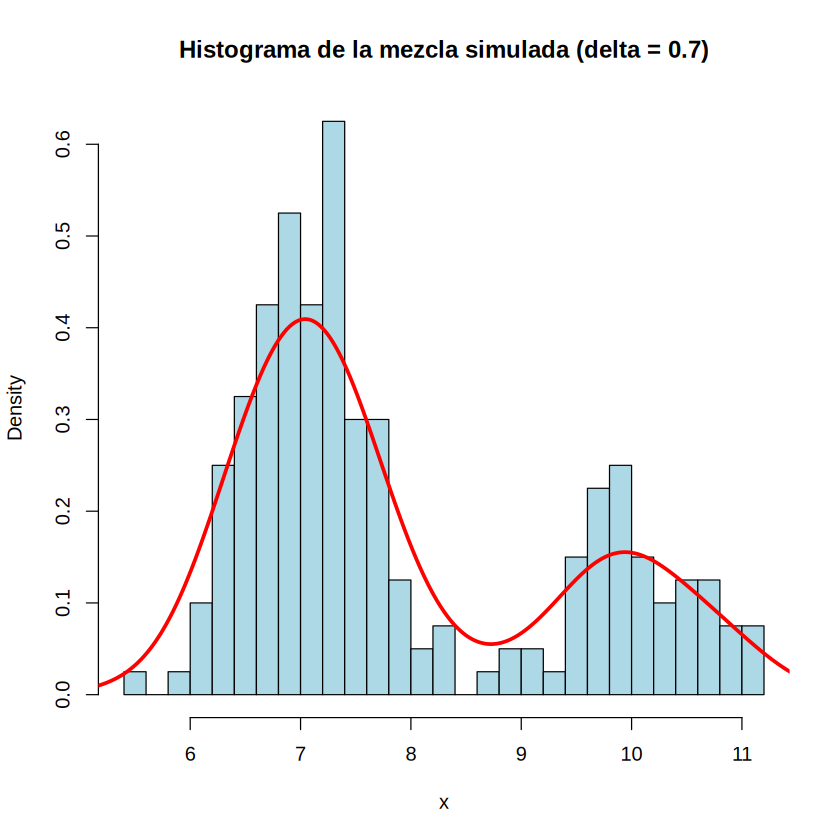

In [28]:
set.seed(777)

n = 200
Delta1 = 0.7

u = runif(n)

componentes = ifelse(u < Delta1,1,2)
x = numeric(n)

x[componentes == 1] = rnorm(sum(componentes == 1),mean = 7,sd = 0.5)
x[componentes == 2] = rnorm(sum(componentes == 2),mean = 10,sd = 0.5)

hist(x,breaks = 25,probability = TRUE,main = "Histograma de la mezcla simulada (delta = 0.7)",xlab = "x",col = "lightblue",border = "black")
lines(density(x),col = 'red',lwd = 3)

### $b)$

*implementaremos un algoritmo MCMC de cadena de independencia (Independence Chain).*

1. Propuesta
En cada paso $t$, proponemos un nuevo $\delta^* \sim \text{Unif}(0,1)$.

---

2. Log-Verosimilitud
Para evitar problemas de precisión numérica (*underflow*) al multiplicar $200$ probabilidades pequeñas, calculamos la log-verosimilitud:

$$\log L(\delta \mid x) = \sum_{i=1}^{n} \log \left[ \delta \cdot f_1(x_i) + (1-\delta) \cdot f_2(x_i) \right]$$

donde:
* $f_1(x_i) = \text{dnorm}(x_i, 7, 0.5)$
* $f_2(x_i) = \text{dnorm}(x_i, 10, 0.5)$

---

3. Probabilidad de Aceptación ($\alpha$)
Dado que la propuesta y la distribución a priori son simétricas y uniformes en $(0,1)$, el cociente de aceptación se reduce a la razón de verosimilitudes:

$$\alpha = \min\left(1, \; \frac{L(\delta^* \mid x)}{L(\delta^{(t)} \mid x)}\right) \implies \log \alpha = \min\left(0, \; \log L(\delta^* \mid x) - \log L(\delta^{(t)} \mid x)\right)$$

---

4. Criterio de Aceptación
Si $\log(u) \le \log \alpha$ con $u \sim \text{Unif}(0,1)$, aceptamos $\delta^{(t+1)} = \delta^*$. De lo contrario, nos quedamos con $\delta^{(t+1)} = \delta^{(t)}$.

In [29]:
set.seed(777)

# log

log_ind = function(delta, datos) {
  if (delta <= 0 || delta >= 1) return(-Inf)

  f1 = dnorm(datos, mean = 7, sd = 0.5)

  f2 = dnorm(datos, mean = 10, sd = 0.5)

  sum(log(delta * f1 + (1 - delta) * f2))
}

# Variables

N = 10000
burn_in = 1000
delta_init = 0.5

cadena = numeric(N)
cadena[1] = delta_init
aceptados = 0


In [30]:
# Algoritmo MCMC

set.seed(777)

for(t in 1:(N-1)){
  delta_prop = runif(1,min = 0,max = 1)
  log_alpha = log_ind(delta_prop,x) - log_ind(cadena[t],x)

  if(log(runif(1)) < log_alpha){
    cadena[t + 1] = delta_prop
    aceptados = aceptados + 1
  } else {
    cadena[t + 1] = cadena[t]
  }
}

# burn-in

cadena_burn = cadena[(burn_in + 1):N]
tasa_aceptacion = aceptados / (N-1)
tasa_aceptacion

[1] 0.09880988

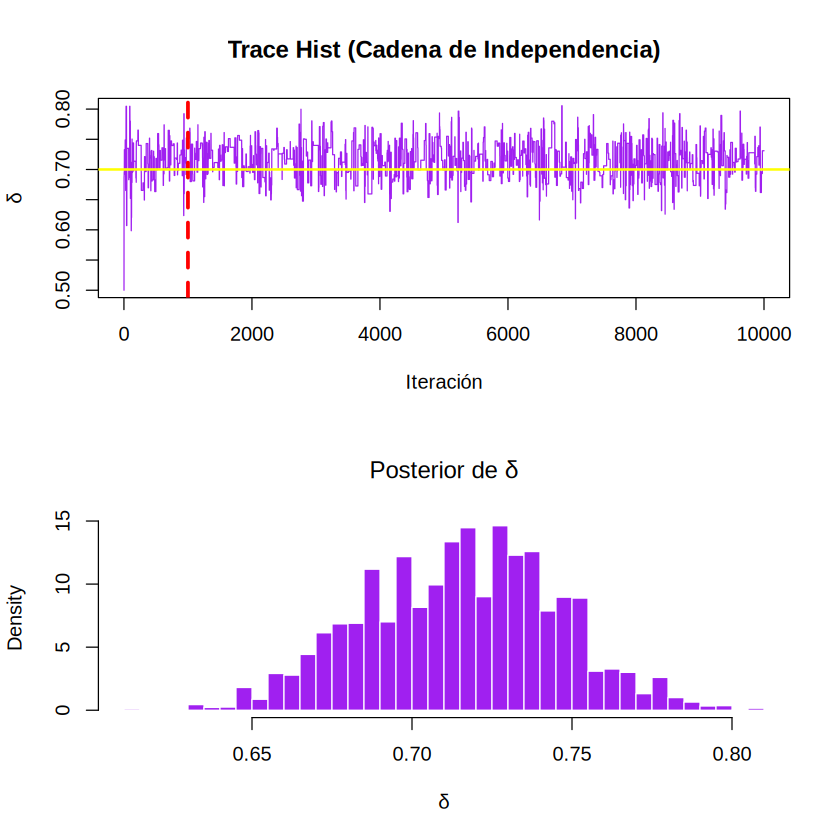

In [31]:
# Graficos

par(mfrow = c(2,1))

plot(cadena,type = "l",col = "purple",main = "Trace Hist (Cadena de Independencia)",xlab = "Iteración", ylab = expression(delta))
abline(v = burn_in,col = "red",lwd = 3, lty = 2)
abline(h = Delta1, col = "yellow", lwd = 2)

hist(cadena_burn, breaks = 30, probability = TRUE,
     col = "purple", border = "white",
     main = expression(paste("Posterior de ", delta)),
     xlab = expression(delta))

In [32]:
resumen_b <- data.frame(
  Algoritmo = "Cadena de Independencia",
  Media_Posterior = mean(cadena_burn),
  Mediana_Posterior = median(cadena_burn),
  Desv_Estd = sd(cadena_burn),
  IC_95_Inf = quantile(cadena_burn, 0.025),
  IC_95_Sup = quantile(cadena_burn, 0.975),
  Tasa_Aceptacion = tasa_aceptacion
)

print(resumen_b)

                   Algoritmo Media_Posterior Mediana_Posterior  Desv_Estd
2.5% Cadena de Independencia       0.7153624          0.716727 0.03016213
     IC_95_Inf IC_95_Sup Tasa_Aceptacion
2.5% 0.6594847 0.7751625      0.09880988


### $c)$

la propuesta para el paso $t+1$ depende del estado actual $\delta^{(t)}$ mediante un desplazamiento uniforme $\varepsilon \sim \text{Unif}(-1,1)$:$$\delta^* = \delta^{(t)} + \varepsilon$$

 1. Propuesta Simétrica
Como la perturbación $\varepsilon$ se distribuye de forma simétrica alrededor de $0$, la densidad de propuesta cumple que:

$$q(\delta^* \mid \delta^{(t)}) = q(\delta^{(t)} \mid \delta^*)$$

Esto significa que los términos de propuesta en la razón de aceptación se cancelan mutuamente.

---

2. Tratamiento de las Fronteras (Soporte)
El parámetro $\delta$ representa una probabilidad, por lo que su soporte estricto es $(0,1)$.

Si la caminata aleatoria propone un candidato $\delta^* \le 0$ o $\delta^* \ge 1$, la densidad a priori en ese punto es $0$, lo que hace que la verosimilitud sea cero ($\log L = -\infty$). Por lo tanto, **esos candidatos se rechazan automáticamente** y el estado de la cadena se mantiene en $\delta^{(t)}$.

---

3. Probabilidad de Aceptación ($\alpha$)

* **Si el candidato es válido ($\delta^* \in (0,1)$):**
  $$\log \alpha = \min\left(0, \; \log L(\delta^* \mid x) - \log L(\delta^{(t)} \mid x)\right)$$

* **Si el candidato está fuera del rango ($\delta^* \notin (0,1)$):**
  $$\alpha = 0 \quad \text{(Rechazo directo)}$$

In [44]:
# Algoritmo Metropolis-Hastings (Random Walk en delta)

set.seed(777)

cadena_c = numeric(N)
cadena_c[1] = delta_init
aceptados_c = 0

for(t in 1:(N-1)){
  epsilon = runif(1,min = -1,max = 1)
  delta_prop = cadena_c[t] + epsilon

  if(delta_prop > 0 && delta_prop < 1){
    log_alpha = log_alpha = log_ind(delta_prop,x) - log_ind(cadena_c[t],x)

    if(log(runif(1)) < log_alpha){
      cadena_c[t + 1] = delta_prop
      aceptados = aceptados + 1
    }else{
      cadena_c[t+1] = cadena_c[t]
    }
  }else{
    cadena_c[t+1] = cadena_c[t]
  }
}

cadena_burnc = cadena_c[(burn_in + 1):N]
aceptacion = aceptados / (N-1)
aceptacion

[1] 0.2471247

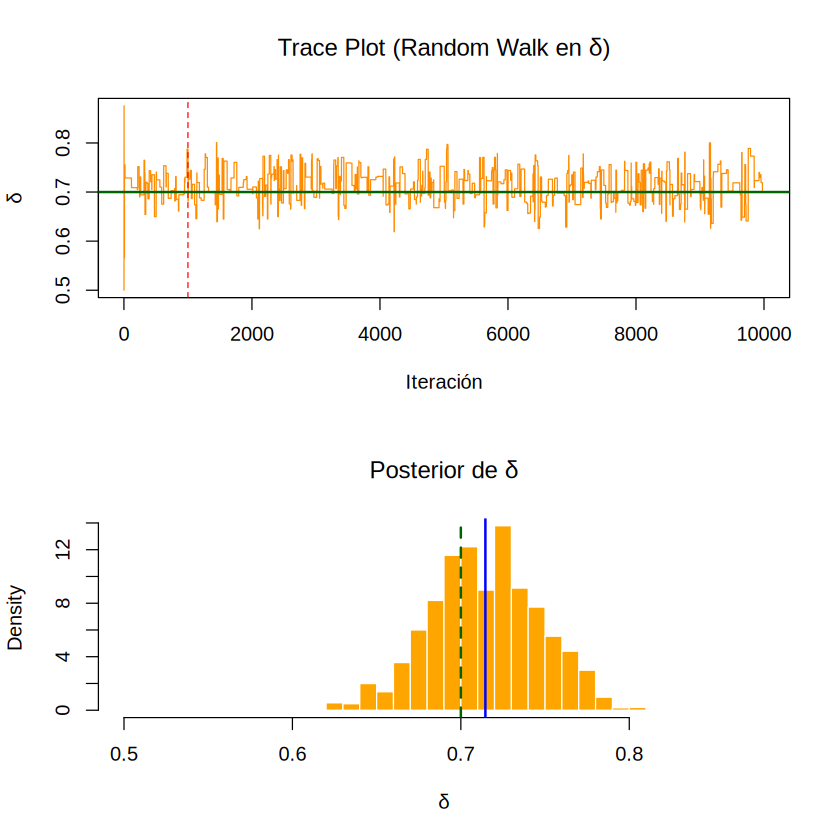

In [51]:
par(mfrow = c(2, 1))

plot(cadena_c, type = "l", col = "darkorange",
     main = expression(paste("Trace Plot (Random Walk en ", delta, ")")),
     xlab = "Iteración", ylab = expression(delta))
abline(v = burn_in, col = "red", lty = 2) # Línea de burn-in
abline(h = Delta1, col = "darkgreen", lwd = 2) # Valor real (0.7)

hist(cadena_c, breaks = 30, probability = TRUE,
     col = "orange", border = "white",
     main = expression(paste("Posterior de ", delta)),
     xlab = expression(delta))
abline(v = mean(cadena_c), col = "blue", lwd = 2)
abline(v = Delta1, col = "darkgreen", lwd = 2, lty = 2)

In [55]:
resumen_c <- data.frame(
  Algoritmo = "Random Walk (delta)",
  Media_Posterior = mean(cadena_c),
  Mediana_Posterior = median(cadena_c),
  Desv_Estd = sd(cadena_c),
  IC_95_Inf = quantile(cadena_c, 0.025),
  IC_95_Sup = quantile(cadena_c, 0.975),
  Tasa_Aceptacion = aceptacion
)

print(resumen_c)


               Algoritmo Media_Posterior Mediana_Posterior  Desv_Estd IC_95_Inf
2.5% Random Walk (delta)       0.7145722         0.7162505 0.03222457 0.6488167
     IC_95_Sup Tasa_Aceptacion
2.5% 0.7730639       0.2471247


### $d)$

1. Caminata Aleatoria en el espacio $U$
La propuesta se realiza directamente sobre el espacio transformado $U$ mediante:
$$U^* = U^{(t)} + \varepsilon$$
donde $\varepsilon \sim \text{Unif}(-1,1)$. Como $U^*$ puede tomar cualquier valor real en la recta numérica, **ya no existen problemas de fronteras** ni propuestas fuera del rango $(0,1)$.

---

2. Transformación de Variables y Jacobiano
Al cambiar de variable de $\delta$ a $U$ (mediante una transformación logística o logit), debemos multiplicar la distribución a posteriori por el valor absoluto de la derivada del cambio de variable, conocido como el **Jacobiano**:

$$\left| \frac{d\delta}{dU} \right| = \frac{e^U}{(1 + e^U)^2} = \delta(1 - \delta)$$

---

3. Probabilidad de Aceptación ($\alpha$)
Dado que la propuesta en el espacio $U$ es simétrica (es decir, $q(U^* \mid U^{(t)}) = q(U^{(t)} \mid U^*)$), la razón de aceptación en la escala $U$ incluye tanto la verosimilitud evaluada en el parámetro propuesto $\delta^*$ (mapeado desde $U^*$) como el término corrector del Jacobiano:

$$\alpha = \min\left(1, \; \frac{L(\delta^* \mid x) \cdot \delta^*(1 - \delta^*)}{L(\delta^{(t)} \mid x) \cdot \delta^{(t)}(1 - \delta^{(t)})}\right)$$

---

4. Versión en Escala Logarítmica
Para implementarlo de forma numérica estable en el código, expresamos la razón de aceptación en escala logarítmica:

$$\log \alpha = \min\left(0, \; \left[\log L(\delta^* \mid x) + \log\big(\delta^*(1 - \delta^*)\big)\right] - \left[\log L(\delta^{(t)} \mid x) + \log\big(\delta^{(t)}(1 - \delta^{(t)})\big)\right]\right)$$

In [74]:
set.seed(777)

N = 10000
burn_in = 1000
delta_init = 0.5
u_init = log(delta_init)

cadena_u = numeric(N)
cadena_d = numeric(N) #

cadena_u[1] = u_init
cadena_d[1] = delta_init
aceptados_d = 0

for(t in 1:(N-1)){
  epsilon = runif(1,min = -1,max = 1)
  u_prop = cadena_u[t] + epsilon

  delta_prop = plogis(u_prop)
  delta_curr = cadena_d[t]

  log_post = log_ind(delta_prop,x) + log(delta_prop * (1-delta_prop))
  log_postc = log_ind(delta_curr,x) + log(delta_curr * (1-delta_curr))

  log_alpha = log_post - log_postc

  if (log(runif(1)) < log_alpha) {
    cadena_u[t + 1] = u_prop
    cadena_d[t + 1] = delta_prop
    aceptados_d = aceptados_d + 1
  } else {
    cadena_u[t + 1] <- cadena_u[t]
    cadena_d[t + 1] <- cadena_d[t]
  }
}
cadena_dburn = cadena_d[(burn_in + 1):N]
tasa_aceptacion_d = aceptados_d / (N - 1)

tasa_aceptacion_d

[1] 0.2512251

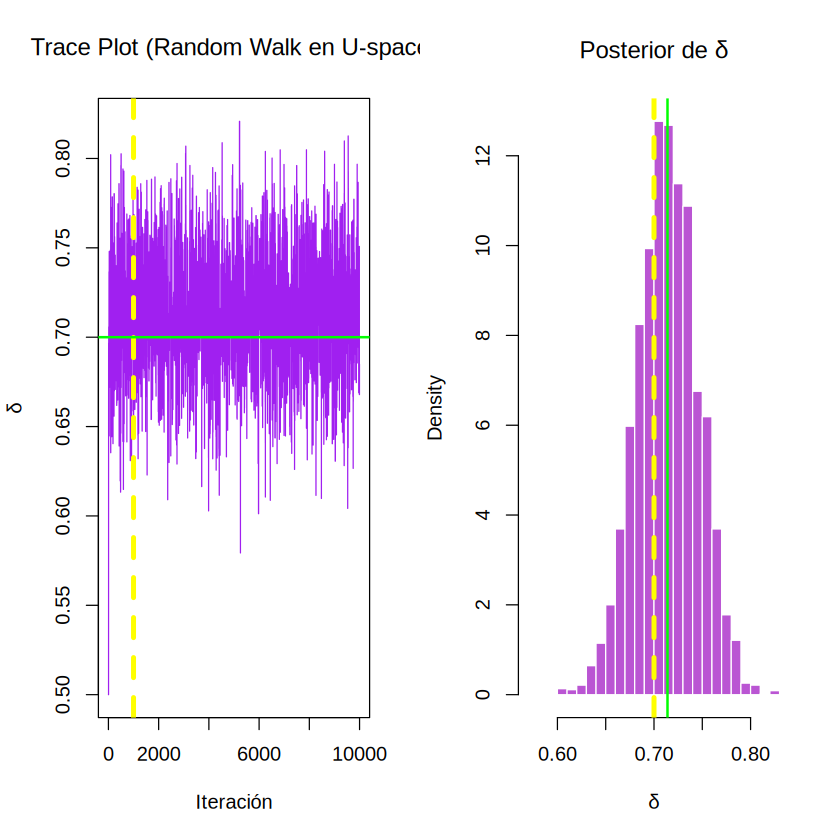

In [87]:
par(mfrow = c(1, 2))


plot(cadena_d, type = "l", col = "purple",
     main = expression(paste("Trace Plot (Random Walk en ", U, "-space)")),
     xlab = "Iteración", ylab = expression(delta))
abline(v = burn_in, col = "yellow", lty = 2,lwd = 4)
abline(h = Delta1, col = "green", lwd = 2)

hist(cadena_dburn, breaks = 30, probability = TRUE,
     col = "mediumorchid", border = "white",
     main = expression(paste("Posterior de ", delta)),
     xlab = expression(delta))
abline(v = mean(cadena_dburn), col = "green", lwd = 2)
abline(v = Delta1, col = "yellow", lwd = 4, lty = 2)

In [89]:
resumen_d <- data.frame(
  Algoritmo = "Random Walk (Espacio U)",
  Media_Posterior = mean(cadena_dburn),
  Mediana_Posterior = median(cadena_dburn),
  Desv_Estd = sd(cadena_dburn),
  IC_95_Inf = quantile(cadena_dburn, 0.025),
  IC_95_Sup = quantile(cadena_dburn, 0.975),
  Tasa_Aceptacion = tasa_aceptacion_d
)

print(resumen_d)

                   Algoritmo Media_Posterior Mediana_Posterior  Desv_Estd
2.5% Random Walk (Espacio U)       0.7139696         0.7134527 0.03153075
     IC_95_Inf IC_95_Sup Tasa_Aceptacion
2.5% 0.6509043 0.7750879       0.2512251


### $e)$


In [91]:
tabla_comparativa = rbind(resumen_b, resumen_c, resumen_d)

# Mostrar la tabla final en consola
print("=== TABLA COMPARATIVA DE LOS TRES ALGORITMOS ===")
print(tabla_comparativa)

[1] "=== TABLA COMPARATIVA DE LOS TRES ALGORITMOS ==="
                    Algoritmo Media_Posterior Mediana_Posterior  Desv_Estd
2.5%  Cadena de Independencia       0.7153624         0.7167270 0.03016213
2.5%1     Random Walk (delta)       0.7145722         0.7162505 0.03222457
2.5%2 Random Walk (Espacio U)       0.7139696         0.7134527 0.03153075
      IC_95_Inf IC_95_Sup Tasa_Aceptacion
2.5%  0.6594847 0.7751625      0.09880988
2.5%1 0.6488167 0.7730639      0.24712471
2.5%2 0.6509043 0.7750879      0.25122512


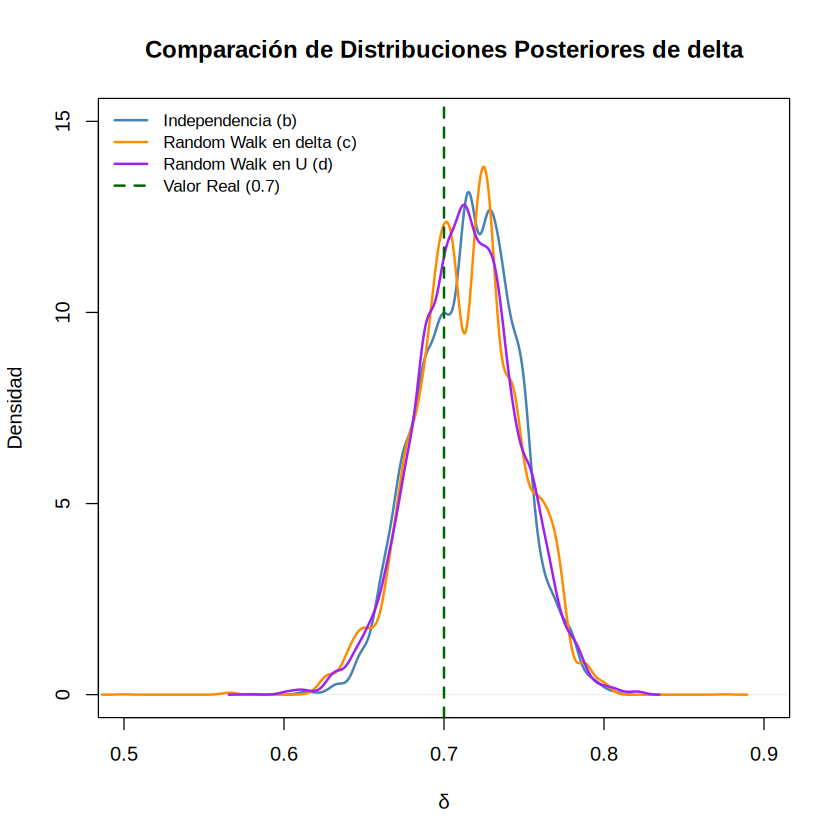

In [97]:
plot(density(cadena_burn), col = "steelblue", lwd = 2,
     xlim = c(0.5, 0.9), ylim = c(0, 15),
     main = "Comparación de Distribuciones Posteriores de delta",
     xlab = expression(delta), ylab = "Densidad")
lines(density(cadena_c), col = "darkorange", lwd = 2)
lines(density(cadena_dburn), col = "purple", lwd = 2)
abline(v = Delta1, col = "darkgreen", lwd = 2, lty = 2)

legend("topleft",
       legend = c("Independencia (b)", "Random Walk en delta (c)", "Random Walk en U (d)", "Valor Real (0.7)"),
       col = c("steelblue", "darkorange", "purple", "darkgreen"),
       lwd = c(2, 2, 2, 2),
       lty = c(1, 1, 1, 2),
       bty = "n",      # Quita el recuadro que tapa el fondo
       cex = 0.85)